# 01 — Khám phá Dữ liệu PGN, Đường ống ETL & Biểu diễn Tensor 18 Kênh

Notebook này trình bày quy trình tiền xử lý dữ liệu từ **Lichess Elite Database** (`chess_ai/etl/pgn_etl.py`), kiểm tra phân chia **Game-level Split (80% / 10% / 10%)**, khử trùng lặp thế cờ bằng **Zobrist 64-bit**, và trực quan hóa biểu diễn **Tensor `(18, 8, 8)` chuẩn hóa góc nhìn bên đi** từ `ChessMemmapDataset`.

In [1]:
import json
from pathlib import Path
import sys

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from chess_ai.etl.memmap_dataset import ChessMemmapDataset, mirror_action_index
from chess_ai.etl.pgn_etl import inspect_raw_pgn, resolve_input_pgn_path

print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: C:\chess\101_TTNTNC


## 1. Thống kê Dữ liệu Thô & Bộ Lọc ETL (Header-First Filtering)

In [2]:
meta_path = PROJECT_ROOT / "data" / "processed" / "dataset_metadata.json"
assert meta_path.exists(), f"Chưa tìm thấy {meta_path}"
meta = json.loads(meta_path.read_text(encoding="utf-8"))

# Nếu có file PGN thô trong data/raw/, quét thêm mẫu Header EDA
try:
    raw_path = resolve_input_pgn_path()
    raw_eda = inspect_raw_pgn(str(raw_path), max_games=5000)
    print("EDA dữ liệu thô (5,000 ván đầu):", json.dumps(raw_eda, ensure_ascii=False, indent=2))
except FileNotFoundError:
    print("Không có tệp PGN thô trong data/raw/ — sử dụng trực tiếp thống kê đã trích xuất từ dataset_metadata.json.")

summary_rows = [
    {"Chỉ tiêu": "Nguồn dữ liệu", "Giá trị": meta.get("source_file")},
    {"Chỉ tiêu": "Tổng số ván đã quét", "Giá trị": f"{meta['games_scanned']:,}"},
    {"Chỉ tiêu": "Số ván hợp lệ (ELO >= 2100, T_est >= 180s)", "Giá trị": f"{meta['valid_games']:,}"},
    {"Chỉ tiêu": "Tổng số mẫu thế cờ trích xuất", "Giá trị": f"{meta['total_samples']:,}"},
    {"Chỉ tiêu": "Thế cờ trùng Zobrist 64-bit đã loại", "Giá trị": f"{meta['zobrist_duplicates_skipped']:,}"},
    {"Chỉ tiêu": "Nước phong cấp dưới đã loại", "Giá trị": f"{meta['underpromotions_skipped']:,}"},
    {"Chỉ tiêu": "Thời gian chạy ETL (giây)", "Giá trị": f"{meta['elapsed_sec']:.2f}s"},
]
display(pd.DataFrame(summary_rows))

Không có tệp PGN thô trong data/raw/ — sử dụng trực tiếp thống kê đã trích xuất từ dataset_metadata.json.


,Chỉ tiêu,Giá trị
0,Nguồn dữ liệu,data\raw\lichess_elite_2025-11.pgn
1,Tổng số ván đã quét,"48,148"
2,"Số ván hợp lệ (ELO >= 2100, T_est >= 180s)","46,748"
3,Tổng số mẫu thế cờ trích xuất,"1,000,000"
4,Thế cờ trùng Zobrist 64-bit đã loại,"62,690"
5,Nước phong cấp dưới đã loại,60
6,Thời gian chạy ETL (giây),118.85s


## 2. Phân Chia Game-Level Split (Train / Val / Test) & Phân Bố Kết Quả Ván Đấu

,Tập dữ liệu,Số ván,Số mẫu,Tỷ lệ mẫu (%)
0,TRAIN,37408,800213,80.02
1,VAL,4659,99432,9.94
2,TEST,4681,100355,10.04


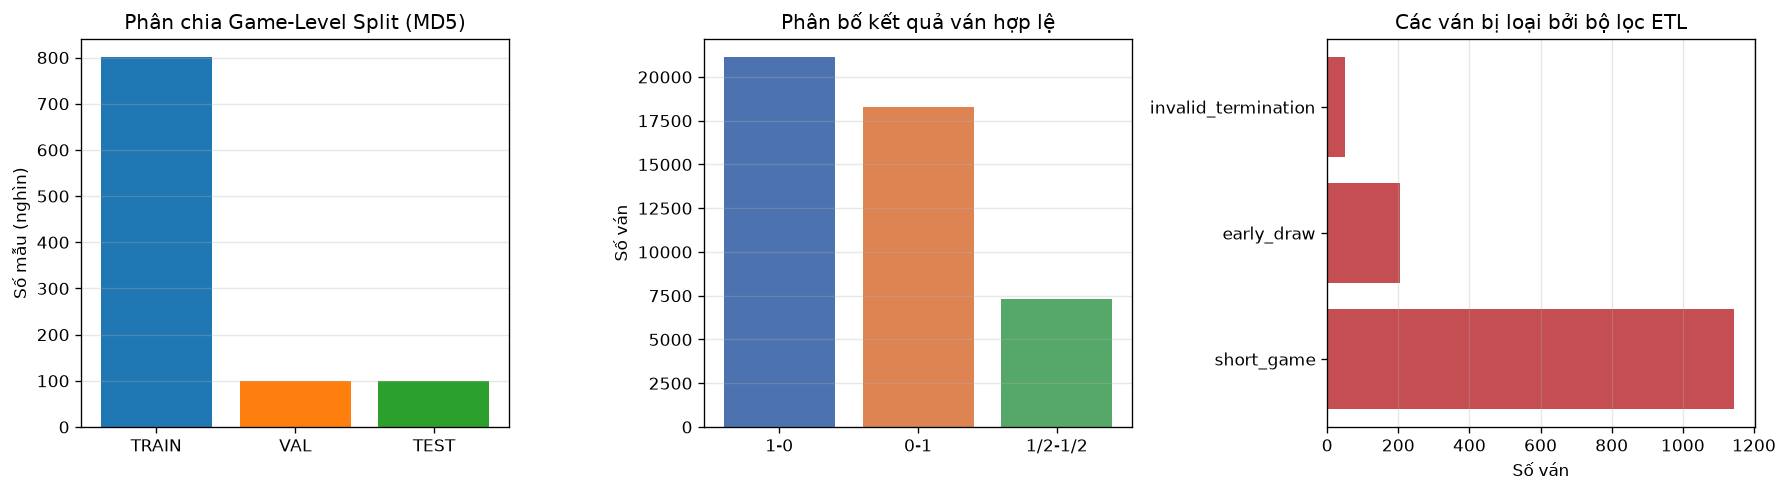

In [3]:
splits_df = pd.DataFrame([
    {
        "Tập dữ liệu": sp.upper(),
        "Số ván": info["games"],
        "Số mẫu": info["samples"],
        "Tỷ lệ mẫu (%)": round(info["samples"] * 100.0 / meta["total_samples"], 2),
    }
    for sp, info in meta["splits"].items()
])
display(splits_df)

res_dist = meta["result_distribution"]
rej = meta.get("rejected_reasons", {})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), dpi=120)

# (1) Train/Val/Test split
axes[0].bar(splits_df["Tập dữ liệu"], splits_df["Số mẫu"] / 1000.0, color=["#1f77b4", "#ff7f0e", "#2ca02c"])
axes[0].set_title("Phân chia Game-Level Split (MD5)")
axes[0].set_ylabel("Số mẫu (nghìn)")
axes[0].grid(True, axis="y", alpha=0.3)

# (2) Phân bố kết quả ván đấu
axes[1].bar(list(res_dist.keys()), list(res_dist.values()), color=["#4c72b0", "#dd8452", "#55a868"])
axes[1].set_title("Phân bố kết quả ván hợp lệ")
axes[1].set_ylabel("Số ván")
axes[1].grid(True, axis="y", alpha=0.3)

# (3) Lý do loại ván
if rej:
    axes[2].barh(list(rej.keys()), list(rej.values()), color="#c44e52")
    axes[2].set_title("Các ván bị loại bởi bộ lọc ETL")
    axes[2].set_xlabel("Số ván")
    axes[2].grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Kiểm Chứng `ChessMemmapDataset`, Tensor `(18, 8, 8)` & Tăng Cường Lật Gương

Dataset train size: 800,213 | state shape: (18, 8, 8) (torch.float32) | action: 405 | value: -1.0
Kiểm tra phép lật gương hành động: 405 -> 82 -> 405
Phân bố nhãn value (50k mẫu đầu): {-1.0: 20116, 0.0: 9811, 1.0: 20073}


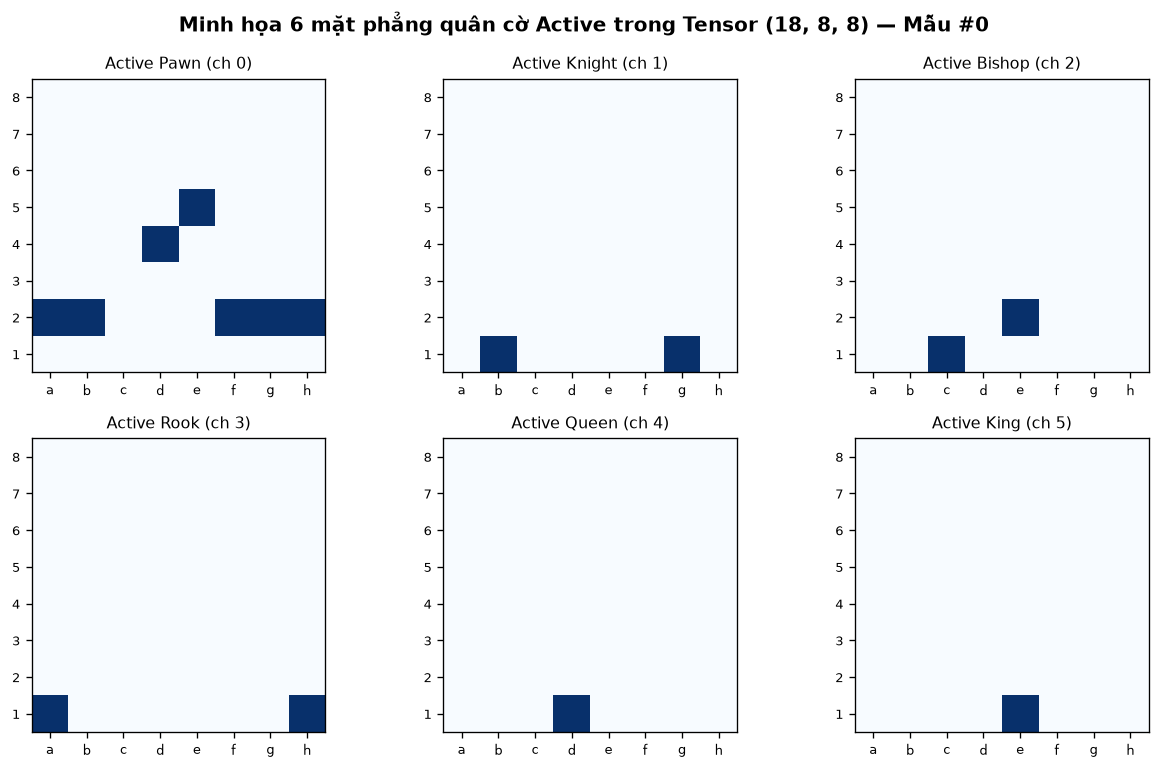

In [4]:
ds_train = ChessMemmapDataset(str(PROJECT_ROOT / "data" / "processed"), split="train", augment_mirror=False)
state_t, action_t, value_t = ds_train[0]
print(f"Dataset train size: {len(ds_train):,} | state shape: {tuple(state_t.shape)} ({state_t.dtype}) | action: {int(action_t)} | value: {float(value_t):+.1f}")
print(f"Kiểm tra phép lật gương hành động: {int(action_t)} -> {mirror_action_index(int(action_t))} -> {mirror_action_index(mirror_action_index(int(action_t)))}")

# Thống kê nhanh phân bố nhãn value trên 50,000 mẫu đầu
sample_vals = np.array(ds_train.values[:50000], dtype=np.float32)
uniq, cnts = np.unique(sample_vals, return_counts=True)
print("Phân bố nhãn value (50k mẫu đầu):", dict(zip(uniq.tolist(), cnts.tolist())))

# Vẽ heatmap 6 mặt phẳng quân cờ của bên tới lượt đi (Active P, N, B, R, Q, K)
plane_names = ["Active Pawn (ch 0)", "Active Knight (ch 1)", "Active Bishop (ch 2)",
               "Active Rook (ch 3)", "Active Queen (ch 4)", "Active King (ch 5)"]
fig, axes = plt.subplots(2, 3, figsize=(10.5, 6.5), dpi=120)
for i, ax in enumerate(axes.flat):
    ax.imshow(state_t[i].numpy()[::-1], cmap="Blues", vmin=0, vmax=1)
    ax.set_title(plane_names[i], fontsize=9.5)
    ax.set_xticks(range(8))
    ax.set_xticklabels(list("abcdefgh"), fontsize=8)
    ax.set_yticks(range(8))
    ax.set_yticklabels(list("87654321"), fontsize=8)
fig.suptitle("Minh họa 6 mặt phẳng quân cờ Active trong Tensor (18, 8, 8) — Mẫu #0", fontweight="bold")
plt.tight_layout()
plt.show()